In [ ]:
!pip install -q pyspark

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("PySpark-Matplotlib-Colab")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)

print("Spark:", spark.version)

Spark: 4.0.4


In [ ]:
N = 200_000

categorias = [
    "Tecnologia",
    "Hogar",
    "Ropa",
    "Alimentos"
]

canales = [
    "Web",
    "App",
    "Tienda"
]

regiones = [
    "Norte",
    "Centro",
    "Sur",
    "Oeste"
]

df = (
    spark.range(N)

    .withColumn(
        "order_date",
        F.date_add(
            F.lit("2026-01-01").cast("date"),
            (F.rand(seed=1) * 180).cast("int")
        )
    )

    .withColumn(
        "customer_id",
        F.concat(
            F.lit("C"),
            F.lpad(
                ((F.rand(seed=2) * 5000).cast("int") + 1).cast("string"),
                5,
                "0"
            )
        )
    )

    .withColumn(
        "category",
        F.element_at(
            F.array(*[F.lit(x) for x in categorias]),
            (F.floor(F.rand(seed=3) * len(categorias)) + 1).cast("int")
        )
    )

    .withColumn(
        "channel",
        F.element_at(
            F.array(*[F.lit(x) for x in canales]),
            (F.floor(F.rand(seed=4) * len(canales)) + 1).cast("int")
        )
    )

    .withColumn(
        "region",
        F.element_at(
            F.array(*[F.lit(x) for x in regiones]),
            (F.floor(F.rand(seed=5) * len(regiones)) + 1).cast("int")
        )
    )

    .withColumn(
        "quantity",
        (F.floor(F.rand(seed=6) * 5) + 1).cast("int")
    )

    .withColumn(
        "unit_price",
        F.round(
            10 + F.rand(seed=7) * 490,
            2
        )
    )

    .withColumn(
        "discount",
        F.round(
            F.rand(seed=8) * 0.25,
            2
        )
    )

    .withColumn(
        "revenue",
        F.round(
            F.col("quantity")
            * F.col("unit_price")
            * (1 - F.col("discount")),
            2
        )
    )

    .drop("id")
)

df.cache()

print("Número de registros:", df.count())

df.show(10)

Número de registros: 200000
+----------+-----------+----------+-------+------+--------+----------+--------+-------+
|order_date|customer_id|  category|channel|region|quantity|unit_price|discount|revenue|
+----------+-----------+----------+-------+------+--------+----------+--------+-------+
|2026-04-25|     C02656|     Hogar| Tienda| Norte|       1|    148.12|    0.12| 130.35|
|2026-04-18|     C01431|      Ropa|    Web| Norte|       4|    235.39|    0.18| 772.08|
|2026-01-25|     C02473| Alimentos|    Web| Oeste|       3|    386.86|    0.06|1090.95|
|2026-01-14|     C02277|      Ropa|    App|   Sur|       5|    334.94|    0.11|1490.48|
|2026-06-03|     C04397|Tecnologia|    Web|Centro|       5|    265.07|    0.19|1073.53|
|2026-05-10|     C01823|Tecnologia|    App| Norte|       3|    452.12|     0.1|1220.72|
|2026-02-14|     C02251| Alimentos|    App|Centro|       1|    149.91|    0.17| 124.43|
|2026-01-25|     C02100| Alimentos| Tienda| Oeste|       4|    496.31|    0.04|1905.83|
|202

In [ ]:
df.count()

200000

Ejercicio 1. Gráfica de barras
Pregunta
¿Qué categorías generan más ingresos?

In [ ]:
ventas_categoria = (
    df
    .groupBy("category")
    .agg(
        F.round(
            F.sum("revenue"),
            2
        ).alias("total_revenue")
    )
    .orderBy(
        F.desc("total_revenue")
    )
)

ventas_categoria.show()

+----------+-------------+
|  category|total_revenue|
+----------+-------------+
|      Ropa|3.360777546E7|
|     Hogar|3.354079376E7|
|Tecnologia|3.346294115E7|
| Alimentos| 3.33480017E7|
+----------+-------------+



In [ ]:
pdf_categoria = ventas_categoria.toPandas()

pdf_categoria

,category,total_revenue
0,Ropa,33607775.46
1,Hogar,33540793.76
2,Tecnologia,33462941.15
3,Alimentos,33348001.70


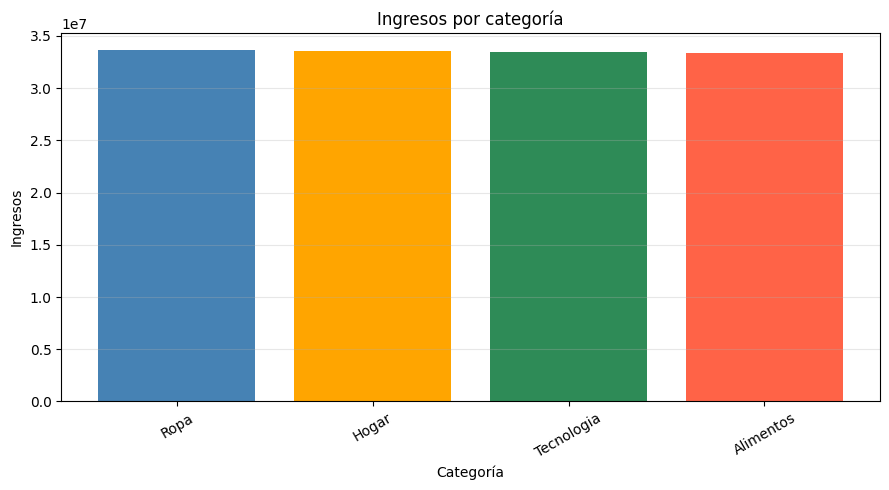

In [ ]:
plt.figure(figsize=(9, 5))

colores = [
    "steelblue",
    "orange",
    "seagreen",
    "tomato"
]

plt.bar(
    pdf_categoria["category"],
    pdf_categoria["total_revenue"],
    color=colores
)

plt.title("Ingresos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Ingresos")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

Ejercicio 2. Serie temporal
Ahora queremos responder:
¿Cómo evolucionan las ventas a lo largo del tiempo?

In [ ]:
ventas_semana = (
    df

    .withColumn(
        "week",
        F.date_trunc(
            "week",
            "order_date"
        )
    )

    .groupBy("week")

    .agg(
        F.sum("revenue").alias("revenue"),
        F.count("*").alias("orders")
    )

    .orderBy("week")
)

ventas_semana.show(10)

+-------------------+-----------------+------+
|               week|          revenue|orders|
+-------------------+-----------------+------+
|2025-12-29 00:00:00|2959954.349999996|  4455|
|2026-01-05 00:00:00|5206722.739999999|  7789|
|2026-01-12 00:00:00|5239568.659999992|  7773|
|2026-01-19 00:00:00|5077642.900000006|  7721|
|2026-01-26 00:00:00| 5234073.90000001|  7854|
|2026-02-02 00:00:00|5109087.299999985|  7596|
|2026-02-09 00:00:00|5173617.989999998|  7738|
|2026-02-16 00:00:00|5281097.049999995|  7899|
|2026-02-23 00:00:00|5168116.009999994|  7797|
|2026-03-02 00:00:00|5275661.730000004|  7836|
+-------------------+-----------------+------+
only showing top 10 rows


In [ ]:
pdf_semana = ventas_semana.toPandas()

pdf_semana["week"] = pd.to_datetime(
    pdf_semana["week"]
)

pdf_semana.head()

,week,revenue,orders
0,2025-12-29,2959954.35,4455
1,2026-01-05,5206722.74,7789
2,2026-01-12,5239568.66,7773
3,2026-01-19,5077642.90,7721
4,2026-01-26,5234073.90,7854


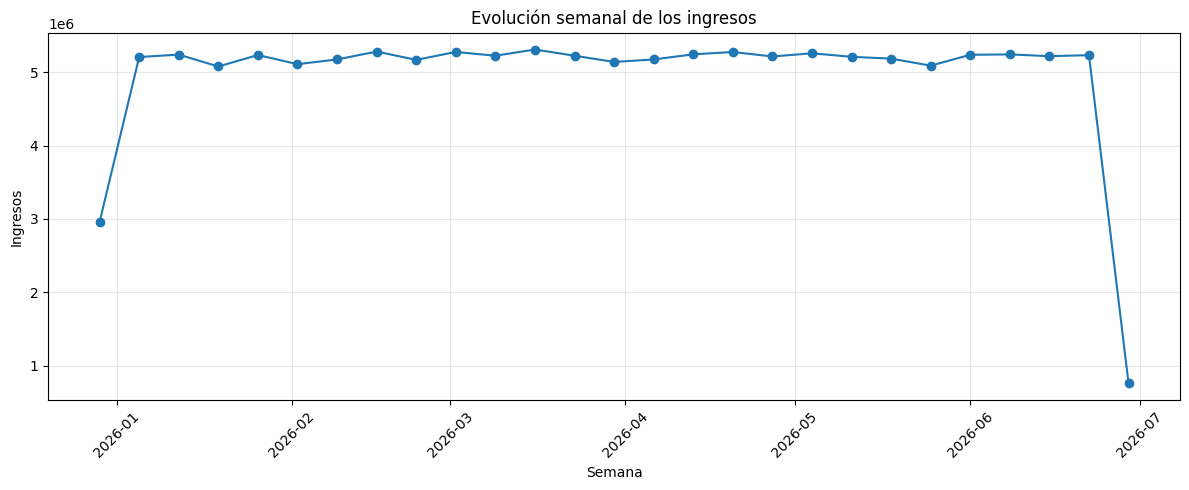

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    pdf_semana["week"],
    pdf_semana["revenue"],
    marker="o"
)

plt.title(
    "Evolución semanal de los ingresos"
)

plt.xlabel("Semana")
plt.ylabel("Ingresos")

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Ejercicio 3. Barras apiladas
Pregunta:
¿Cómo se distribuyen los ingresos entre Web, App y Tienda en cada región?

In [ ]:
region_canal = (
    df

    .groupBy("region")

    .pivot(
        "channel",
        ["Web", "App", "Tienda"]
    )

    .agg(
        F.sum("revenue")
    )

    .fillna(0)

    .orderBy("region")
)

region_canal.show()

+------+--------------------+--------------------+--------------------+
|region|                 Web|                 App|              Tienda|
+------+--------------------+--------------------+--------------------+
|Centro|1.1204284380000006E7|1.1332824050000023E7|1.1180325629999988E7|
| Norte| 1.103664299000002E7|1.1123175010000039E7|1.1215103670000026E7|
| Oeste| 1.119634749999997E7|1.1094108490000002E7|1.1115587539999994E7|
|   Sur| 1.118134122999996E7| 1.122534151000002E7|       1.105443007E7|
+------+--------------------+--------------------+--------------------+



In [ ]:
pdf_region = region_canal.toPandas()

pdf_region

,region,Web,App,Tienda
0,Centro,11204284.38,11332824.05,11180325.63
1,Norte,11036642.99,11123175.01,11215103.67
2,Oeste,11196347.50,11094108.49,11115587.54
3,Sur,11181341.23,11225341.51,11054430.07


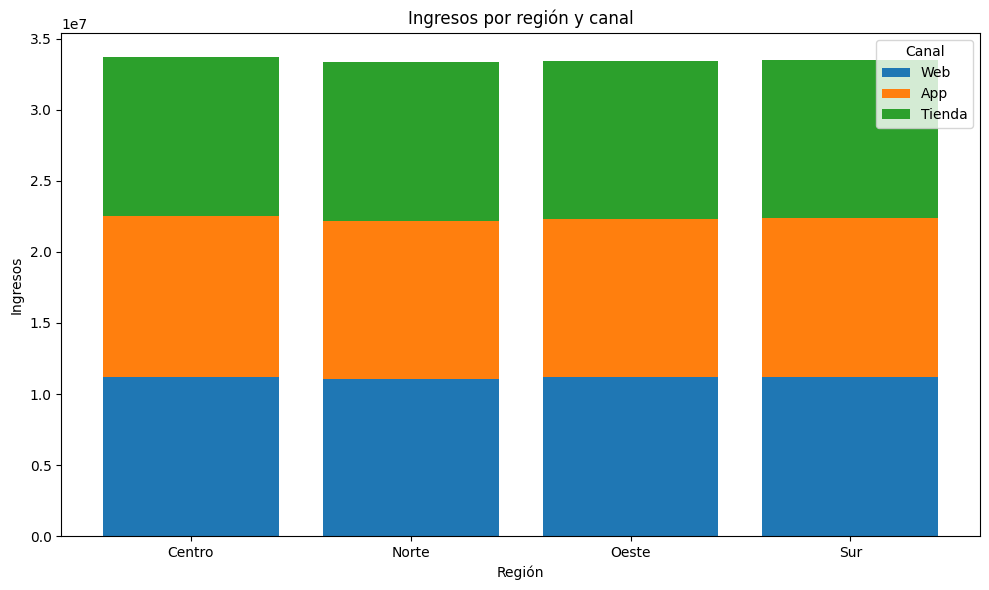

In [ ]:
x = np.arange(
    len(pdf_region)
)



bottom = np.zeros(
    len(pdf_region)
)

plt.figure(figsize=(10, 6))

for canal in ["Web", "App", "Tienda"]:

    valores = pdf_region[canal].values

    plt.bar(
        x,
        valores,
        bottom=bottom,
        label=canal
    )

    bottom += valores

plt.xticks(
    x,
    pdf_region["region"]
)

plt.title(
    "Ingresos por región y canal"
)

plt.xlabel("Región")
plt.ylabel("Ingresos")

plt.legend(
    title="Canal"
)

plt.tight_layout()
plt.show()

Ejercicio 4. Scatter plot de clientes
Ahora una pregunta analítica:
¿Los clientes que compran muchas veces tienen un ticket medio más alto?

In [ ]:
clientes = (
    df

    .groupBy(
        "customer_id"
    )

    .agg(
        F.count("*")
        .alias("num_orders"),

        F.avg("revenue")
        .alias("avg_ticket"),

        F.sum("revenue")
        .alias("total_spend")
    )
)

clientes.show(10)

+-----------+----------+-----------------+------------------+
|customer_id|num_orders|       avg_ticket|       total_spend|
+-----------+----------+-----------------+------------------+
|     C02472|        51|636.1478431372549|          32443.54|
|     C03178|        30|651.0166666666667|           19530.5|
|     C00049|        36|675.8358333333332|24330.089999999997|
|     C03292|        33|681.0093939393938|22473.309999999998|
|     C03941|        46|683.2447826086957|31429.260000000002|
|     C02165|        44|606.3020454545455|          26677.29|
|     C00394|        38|623.1718421052632|          23680.53|
|     C01720|        42|593.9695238095238|          24946.72|
|     C00169|        36|657.9741666666665|23687.069999999996|
|     C02501|        36|622.4966666666667|          22409.88|
+-----------+----------+-----------------+------------------+
only showing top 10 rows


In [ ]:
pdf_clientes = clientes.toPandas()
pdf_clientes

,customer_id,num_orders,avg_ticket,total_spend
0,C02472,51,636.147843,32443.54
1,C03178,30,651.016667,19530.50
2,C00049,36,675.835833,24330.09
3,C03292,33,681.009394,22473.31
4,C03941,46,683.244783,31429.26
...,...,...,...,...
4995,C00837,48,734.779167,35269.40
4996,C01760,40,657.472250,26298.89
4997,C03278,29,599.767931,17393.27
4998,C04455,42,813.393095,34162.51


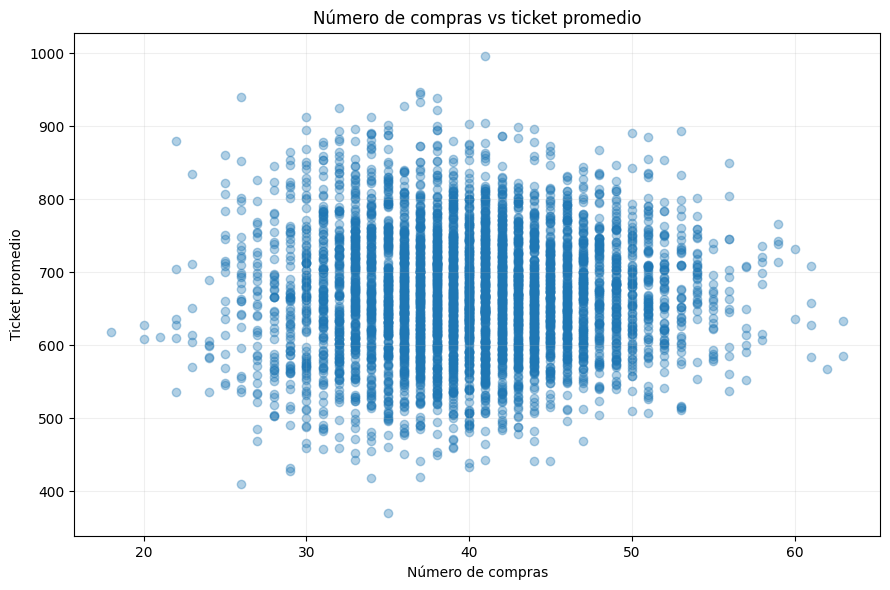

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pdf_clientes["num_orders"],
    pdf_clientes["avg_ticket"],
    alpha=0.35
)

plt.title(
    "Número de compras vs ticket promedio"
)

plt.xlabel(
    "Número de compras"
)

plt.ylabel(
    "Ticket promedio"
)

plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Ejercicio 5. Histograma utilizando sampling
Este ejercicio sirve especialmente para explicar por qué usamos Spark.
Tenemos 200.000 operaciones, pero para visualizar una distribución no necesariamente necesitamos descargar las 200.000.

In [ ]:
muestra = (
    df
    .select("revenue")
    .sample(
        withReplacement=False,
        fraction=0.05,
        seed=42
    )
    .limit(10_000)
)

print(
    "Registros de la muestra:",
    muestra.count()
)

Registros de la muestra: 10000


In [ ]:
pdf_muestra = muestra.toPandas()

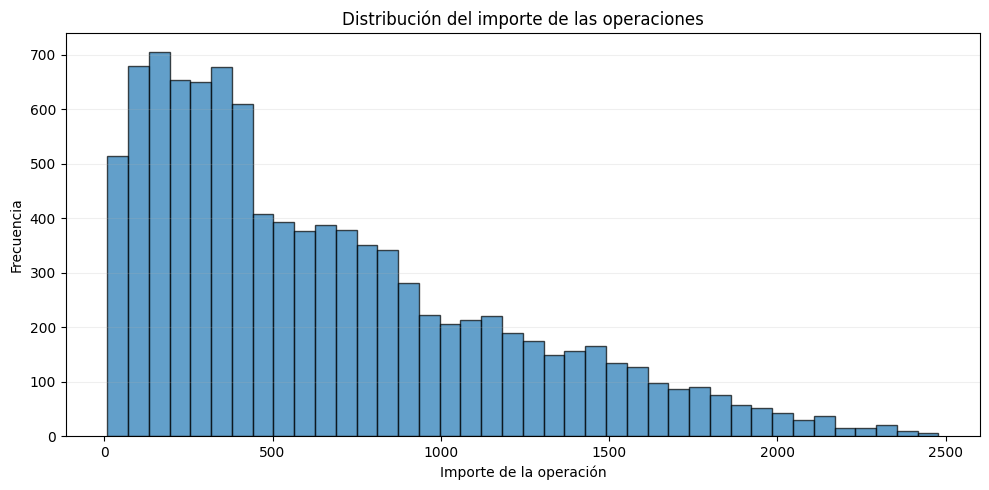

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    pdf_muestra["revenue"],
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.title(
    "Distribución del importe de las operaciones"
)

plt.xlabel(
    "Importe de la operación"
)

plt.ylabel(
    "Frecuencia"
)

plt.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()
plt.show()

Ejercicio 6. Top 10 clientes
Pregunta:
¿Quiénes son nuestros diez clientes con mayor facturación?

In [ ]:
top_clientes = (
    df

    .groupBy(
        "customer_id"
    )

    .agg(
        F.sum("revenue")
        .alias("total_revenue")
    )

    .orderBy(
        F.desc("total_revenue")
    )

    .limit(10)
)

top_clientes.show()

+-----------+------------------+
|customer_id|     total_revenue|
+-----------+------------------+
|     C00388|          47618.33|
|     C04443|47340.520000000004|
|     C02930|45238.369999999995|
|     C03360|          45148.75|
|     C00017| 45080.01999999999|
|     C03801|          44577.47|
|     C00649|          44399.34|
|     C01926| 44152.71000000001|
|     C04772|43920.579999999994|
|     C04912|43806.219999999994|
+-----------+------------------+



In [ ]:
pdf_top = top_clientes.toPandas()

pdf_top = pdf_top.sort_values(
    "total_revenue",
    ascending=True
)

pdf_top

,customer_id,total_revenue
9,C04912,43806.22
8,C04772,43920.58
7,C01926,44152.71
6,C00649,44399.34
5,C03801,44577.47
4,C00017,45080.02
3,C03360,45148.75
2,C02930,45238.37
1,C04443,47340.52
0,C00388,47618.33


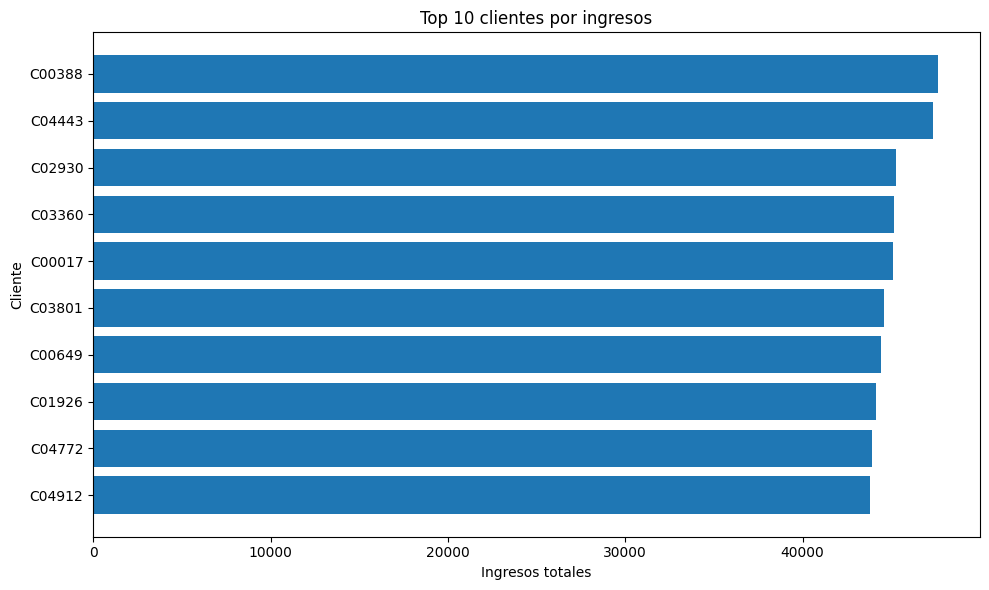

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    pdf_top["customer_id"],
    pdf_top["total_revenue"]
)

plt.title(
    "Top 10 clientes por ingresos"
)

plt.xlabel(
    "Ingresos totales"
)

plt.ylabel(
    "Cliente"
)

plt.tight_layout()
plt.show()

Ejercicio 7. Heatmap región × categoría
Pregunta:
¿Qué categorías funcionan mejor en cada región?

In [ ]:
heatmap_df = (
    df

    .groupBy("region")

    .pivot(
        "category",
        categorias
    )

    .agg(
        F.sum("revenue")
    )

    .fillna(0)

    .orderBy("region")
)

heatmap_df.show()

+------+-----------------+-----------------+-----------------+-----------------+
|region|       Tecnologia|            Hogar|             Ropa|        Alimentos|
+------+-----------------+-----------------+-----------------+-----------------+
|Centro|8421949.309999999|8379488.479999996|8431886.550000004|8484109.719999991|
| Norte|8374437.700000009|8418276.239999995|8305487.309999999|       8276720.42|
| Oeste|8377529.750000004|8310358.479999992|8330292.889999993|8387862.410000017|
|   Sur|8289024.390000003|8432670.560000017|8540108.709999997|       8199309.15|
+------+-----------------+-----------------+-----------------+-----------------+



In [ ]:
pdf_heatmap = heatmap_df.toPandas()

matriz = (
    pdf_heatmap
    .set_index("region")[categorias]
)

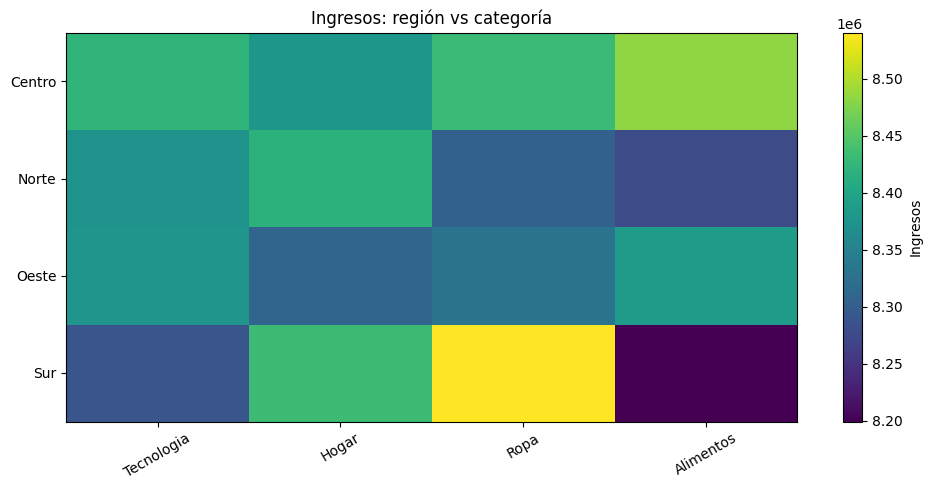

In [ ]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

imagen = ax.imshow(
    matriz.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(categorias))
)

ax.set_xticklabels(
    categorias,
    rotation=30
)

ax.set_yticks(
    range(len(matriz.index))
)

ax.set_yticklabels(
    matriz.index
)

ax.set_title(
    "Ingresos: región vs categoría"
)

plt.colorbar(
    imagen,
    label="Ingresos"
)

plt.tight_layout()
plt.show()